# Community health

**Question:** how many people keep the wiki going, and how concentrated is the work? What share of edits comes from
the most active 1% of editors?

**Data:** the `edits` table built by `pipeline/build_tables.py`: human edits in 2008–2025, the years of the newcomer
cohorts. Definitions are in [docs/metrics_definitions.md](../../docs/metrics_definitions.md):

- **Active editors (decision 9):** per calendar month, registered editors with at least 1 human edit (editors),
  5+ (active) and 100+ (very active).
- **Logged-out editors (decision 3):** anonymous editors and temporary accounts. They can't be counted as people,
  so they appear as a share of edits.
- **Concentration of work (decision 14):** per calendar year, the share of registered editors' edits made by the
  top 1% of editors, and the number of editors who together make half of all edits.

In [1]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd

DB_PATH = Path.cwd().parents[1] / "data" / "wiki.duckdb"
con = duckdb.connect(str(DB_PATH), read_only=True)


def query(sql):
    # Plain numeric types, ready for charts
    return con.sql(sql).df()


# Chart style: one hue per series, recessive grid and axes, text in neutral ink
BLUE, ORANGE = "#2a78d6", "#eb6834"
TEXT, TEXT_MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": TEXT_MUTED, "xtick.color": TEXT_MUTED, "ytick.color": TEXT_MUTED,
    "text.color": TEXT, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

## 1. Active editors

The number of registered editors per calendar month. Monthly counts move with holidays and one-off events, so the
charts show each year's average month, and the table also gives each year's lowest and highest month.

In [2]:
monthly = query("""
    with per_editor_month as (
        select date_trunc('month', event_timestamp) as edit_month, user_id, count(*) as edits
        from edits
        where editor_type = 'registered'
          and year(event_timestamp) between 2008 and 2025
        group by all
    )
    select
        edit_month,
        count(*) as editors,
        count(*) filter (where edits >= 5) as active_editors,
        count(*) filter (where edits >= 100) as very_active_editors
    from per_editor_month
    group by edit_month
    order by edit_month
""")
monthly["year"] = monthly["edit_month"].dt.year

print(f"months: {len(monthly)}; median per month: {monthly['editors'].median():,.1f} editors, "
      f"{monthly['active_editors'].median():,.0f} active, {monthly['very_active_editors'].median():,.0f} very active")

yearly = monthly.groupby("year").agg(
    editors_avg=("editors", "mean"),
    active_avg=("active_editors", "mean"),
    active_min=("active_editors", "min"),
    active_max=("active_editors", "max"),
    very_active_avg=("very_active_editors", "mean"),
)
yearly.round(0).astype(int)

months: 216; median per month: 1,088.5 editors, 254 active, 33 very active


,editors_avg,active_avg,active_min,active_max,very_active_avg
year,,,,,
2008,1028,271,222,325,37
2009,1254,293,251,346,35
2010,1154,256,210,294,36
2011,1033,239,198,290,31
2012,995,242,191,288,30
2013,863,208,142,278,31
2014,803,180,156,199,27
2015,860,195,179,226,24
2016,854,185,146,214,25


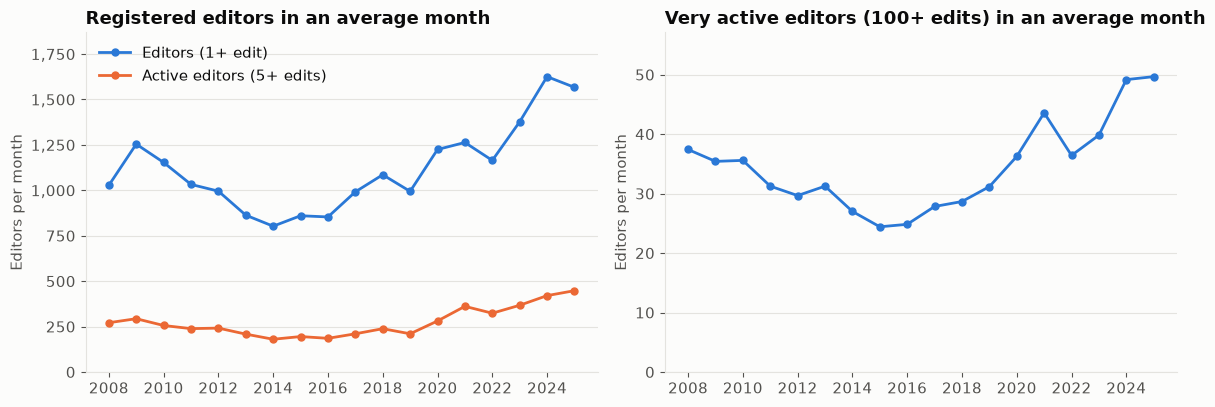

In [3]:
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4.2))

left.plot(yearly.index, yearly["editors_avg"], color=BLUE, linewidth=2, marker="o", markersize=5,
          label="Editors (1+ edit)")
left.plot(yearly.index, yearly["active_avg"], color=ORANGE, linewidth=2, marker="o", markersize=5,
          label="Active editors (5+ edits)")
left.set_title("Registered editors in an average month")
left.set_ylabel("Editors per month")
left.set_ylim(0, yearly["editors_avg"].max() * 1.15)
left.legend(frameon=False, loc="upper left")

right.plot(yearly.index, yearly["very_active_avg"], color=BLUE, linewidth=2, marker="o", markersize=5)
right.set_title("Very active editors (100+ edits) in an average month")
right.set_ylabel("Editors per month")
right.set_ylim(0, yearly["very_active_avg"].max() * 1.15)

for ax in (left, right):
    ax.set_xticks(range(2008, 2026, 2))
    ax.yaxis.set_major_formatter(lambda value, _: f"{value:,.0f}")
plt.tight_layout()
plt.show()

## 2. Logged-out editors

The share of all human edits made by logged-out editors. Temporary accounts replaced anonymous (IP) editing in
September 2025, so 2025 includes both.

In [4]:
logged_out = query("""
    select
        year(event_timestamp) as year,
        count(*) as human_edits,
        count(*) filter (where editor_type = 'logged_out') as logged_out_edits,
        100 * avg((editor_type = 'logged_out')::int) as logged_out_pct
    from edits
    where year(event_timestamp) between 2008 and 2025
    group by 1
    order by 1
""").set_index("year")
logged_out.round(1)

,human_edits,logged_out_edits,logged_out_pct
year,,,
2008,381675,85334,22.4
2009,341599,81841,24.0
2010,328222,75153,22.9
2011,304245,63426,20.8
2012,416288,69902,16.8
2013,388701,80637,20.7
2014,287336,69488,24.2
2015,251003,73175,29.2
2016,247370,69620,28.1


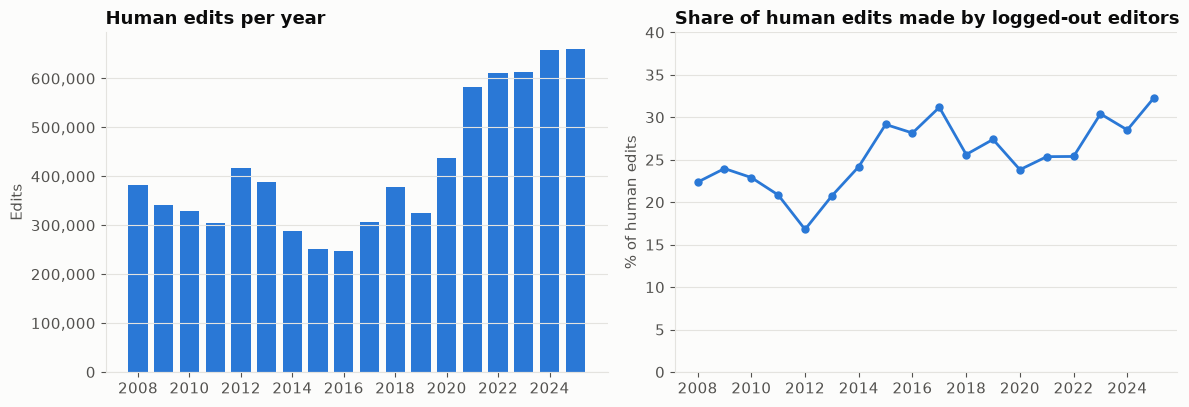

In [5]:
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4.2))

left.bar(logged_out.index, logged_out["human_edits"], color=BLUE, width=0.75)
left.set_title("Human edits per year")
left.set_ylabel("Edits")
left.yaxis.set_major_formatter(lambda value, _: f"{value:,.0f}")

right.plot(logged_out.index, logged_out["logged_out_pct"], color=BLUE, linewidth=2, marker="o", markersize=5)
right.set_title("Share of human edits made by logged-out editors")
right.set_ylabel("% of human edits")
right.set_ylim(0, 40)

for ax in (left, right):
    ax.set_xticks(range(2008, 2026, 2))
plt.tight_layout()
plt.show()

## 3. How concentrated the work is

Each year, registered editors are ranked by their number of human edits that year. The **top 1%** is the first 1% of
that ranking, rounded up, with ties broken by account ID so the result is the same every run. The second measure
counts down the same ranking until half of the year's edits are reached.

In [6]:
concentration = query("""
    with per_editor as (
        select year(event_timestamp) as year, user_id, count(*) as edits
        from edits
        where editor_type = 'registered'
          and year(event_timestamp) between 2008 and 2025
        group by all
    ),
    ranked as (
        select
            *,
            row_number() over (partition by year order by edits desc, user_id) as editor_rank,
            count(*) over (partition by year) as editors_in_year,
            sum(edits) over (partition by year order by edits desc, user_id) as edits_up_to_this_editor,
            sum(edits) over (partition by year) as edits_in_year
        from per_editor
    )
    select
        year,
        any_value(editors_in_year) as editors,
        any_value(edits_in_year) as edits,
        count(*) filter (where editor_rank <= ceil(0.01 * editors_in_year)) as top_1pct_editors,
        100 * sum(edits) filter (where editor_rank <= ceil(0.01 * editors_in_year)) / any_value(edits_in_year)
            as top_1pct_share,
        100 * sum(edits) filter (where editor_rank <= ceil(0.10 * editors_in_year)) / any_value(edits_in_year)
            as top_10pct_share,
        -- the first editor in the ranking at whom the running total reaches half of the year's edits
        min(editor_rank) filter (where edits_up_to_this_editor >= 0.5 * edits_in_year) as editors_making_half,
        median(edits) as median_edits_per_editor
    from ranked
    group by year
    order by year
""").set_index("year")
concentration.round(1)

,editors,edits,top_1pct_editors,top_1pct_share,top_10pct_share,editors_making_half,median_edits_per_editor
year,,,,,,,
2008,7343,296341.0,74,74.2,92.6,21,2.0
2009,9790,259758.0,98,73.2,91.1,26,2.0
2010,9005,253069.0,91,76.6,92.2,23,2.0
2011,8067,240819.0,81,77.0,92.6,18,2.0
2012,7974,346386.0,80,84.6,94.6,7,2.0
2013,7121,308064.0,72,83.8,94.9,7,2.0
2014,6721,217848.0,68,81.0,93.7,11,2.0
2015,7315,177828.0,74,77.7,91.7,11,2.0
2016,7377,177750.0,74,78.1,92.3,13,1.0


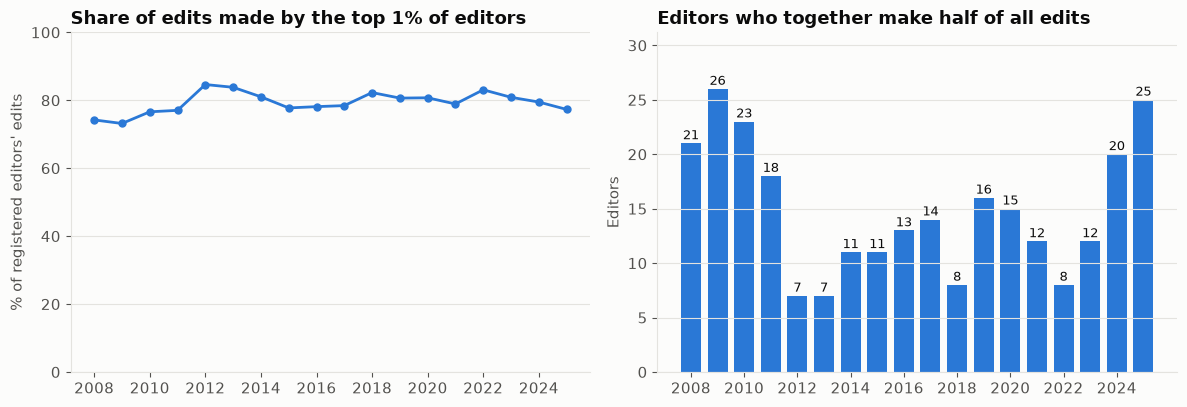

In [7]:
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4.2))

left.plot(concentration.index, concentration["top_1pct_share"], color=BLUE, linewidth=2, marker="o", markersize=5)
left.set_title("Share of edits made by the top 1% of editors")
left.set_ylabel("% of registered editors' edits")
left.set_ylim(0, 100)

right.bar(concentration.index, concentration["editors_making_half"], color=BLUE, width=0.75)
for year, value in concentration["editors_making_half"].items():
    right.annotate(f"{value:.0f}", (year, value), xytext=(0, 3), textcoords="offset points", ha="center",
                   fontsize=9, color=TEXT)
right.set_title("Editors who together make half of all edits")
right.set_ylabel("Editors")
right.set_ylim(0, concentration["editors_making_half"].max() * 1.2)

for ax in (left, right):
    ax.set_xticks(range(2008, 2026, 2))
plt.tight_layout()
plt.show()

## Findings

**1. The wiki's editor base shrank until 2014, then grew past its earlier size.** In an average month there were
1,254 registered editors in 2009, 803 in 2014 and 1,626 in 2024 (1,567 in 2025). Active editors (5+ edits a month)
went from 293 to 180 and then to 448 in 2025, the highest of the period. Very active editors (100+) went from 37
(2008) to 24 (2015) and then to 50 (2025).

**2. The amount of editing followed the same path.** Human edits per year fell from 381,675 (2008) to 247,370 (2016)
and rose to 661,226 (2025).

**3. Logged-out editors make a growing share of the edits.** Their share of human edits was 16.8–24.0% in
2008–2013 and 24–32% from 2014 on, reaching 32.3% in 2025. Since September 2025 this includes temporary accounts.

**4. Most of the work is done by very few people, and that hasn't changed.** Every year the top 1% of registered
editors (68–146 people) made 73.2–84.6% of the edits, and the top 10% made 91–95%. The median editor made 1 or 2
edits in the year. There is no trend in either share over 2008–2025.

**5. Half of each year's edits came from 7 to 26 people.** It was 7 in 2012 and 2013. Since 2022 it rose from 8 to
25, as the number of very active editors grew from 36 to 50 a month, so the work is now spread across slightly
more people.

**6. What this means for newcomer retention:** with a core this small, each newcomer who grows into a very active
editor makes a visible difference. Notebook 01 showed that more newcomers stay each year now mainly because cohorts
grew, while the share who stay (5.3–5.8% in 2022–2025) is still well under half its 2008 level (14.3%). Keeping
more of each cohort is the lever that remains.